# Introduction to EDA Visualization
Definition: Exploratory Data Analysis (EDA) visualization is the process of representing data through graphs and charts to understand patterns, distributions, relationships, trends, and unusual values.
Matplotlib and Seaborn are Python libraries used to create these visualizations. Instead of examining thousands of rows manually, graphs help us understand data more quickly.

In [1]:
%mamba install pandas

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 4.342 seconds
  Name    Version  Build                Channel
-------------------------------------------------------------
+ pandas  3.1.0    np23py313h124dbc7_0  emscripten-forge-4x
- pip     26.2.2   pyh145f28c_0         conda-forge


In [2]:
%mamba install seaborn

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, seaborn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 2.217 seconds
  Name          Version  Build                Channel
-------------------------------------------------------------------
+ patsy         1.0.3    py313h1804a44_0      emscripten-forge-4x
+ seaborn       0.13.2   hd8ed1ab_3           conda-forge
+ seaborn-base  0.13.2   pyhd8ed1ab_3         conda-forge
+ statsmodels   0.15.0   np23py313h07ed413_0  emscripten-forge-4x


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [4]:
df = pd.DataFrame({
    "Employee": [
        "Asha", "Rahul", "Priya", "Arun", "Sneha",
        "Kiran", "Divya", "Vijay", "Meena", "Ravi"
    ],
    "Department": [
        "IT", "HR", "IT", "Sales", "HR",
        "Sales", "IT", "Sales", "HR", "IT"
    ],
    "Age": [23, 28, 25, 35, 30, 40, 27, 32, 29, 26],
    "Experience": [1, 4, 2, 10, 6, 15, 3, 8, 5, 2],
    "Salary": [
        30000, 45000, 35000, 65000, 50000,
        80000, 40000, 60000, 48000, 36000
    ],
    "Performance": [75, 82, 88, 70, 85, 78, 92, 80, 86, 90],
    "Monthly_Sales": [
        12000, 15000, 18000, 22000, 17000,
        25000, 20000, 24000, 16000, 21000
    ]
})

df

,Employee,Department,Age,Experience,Salary,Performance,Monthly_Sales
0,Asha,IT,23,1,30000,75,12000
1,Rahul,HR,28,4,45000,82,15000
2,Priya,IT,25,2,35000,88,18000
3,Arun,Sales,35,10,65000,70,22000
4,Sneha,HR,30,6,50000,85,17000
5,Kiran,Sales,40,15,80000,78,25000
6,Divya,IT,27,3,40000,92,20000
7,Vijay,Sales,32,8,60000,80,24000
8,Meena,HR,29,5,48000,86,16000
9,Ravi,IT,26,2,36000,90,21000


## Histogram
Definition: A histogram displays the frequency of numerical values grouped into intervals called bins.

### Why was it selected?

A histogram helps us understand how a numerical variable is distributed. We can identify where most values fall, whether the data is skewed, and whether there are gaps or unusual patterns.

### Example question: 
What is the salary distribution of employees?

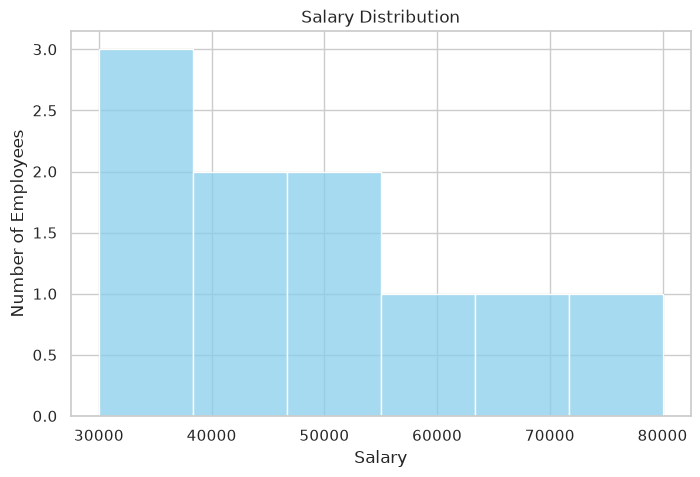

In [5]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Salary", bins=6, color="skyblue")

plt.title("Salary Distribution")
plt.xlabel("Salary")
plt.ylabel("Number of Employees")
plt.show()

### How to interpret the graph
- The X-axis represents salary ranges.
- The Y-axis represents the number of employees in each range.
- Taller bars indicate salary ranges containing more employees.
- The overall shape shows whether salaries are concentrated in a particular range.
### Insight obtained: 
We can identify the salary ranges where employees are concentrated and whether the dataset contains relatively few high-salary employees.

### AI/ML use case: 
Histograms help data scientists understand feature distributions before scaling numerical features or investigating skewness.

## Box Plot
Definition: A box plot summarizes a numerical variable using its median, quartiles, spread, and potential outliers.

### Why was it selected?

A box plot is useful when we want to understand the spread of numerical data and identify possible outliers. It is also helpful for comparing distributions across categories.

### Example question: 
Are there employees whose salaries are unusually high or low compared with the rest?

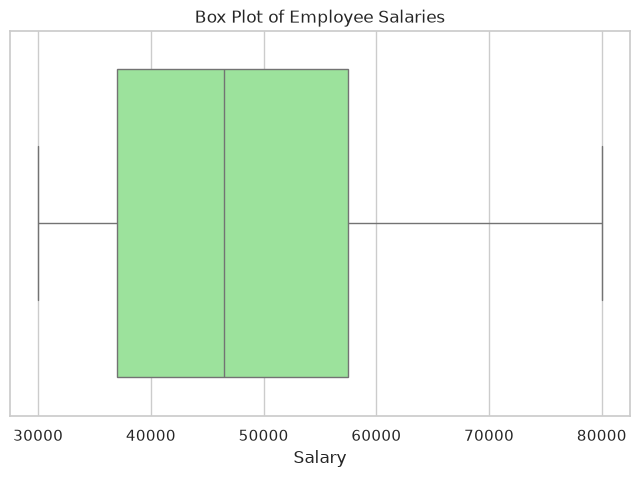

In [6]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Salary", color="lightgreen")

plt.title("Box Plot of Employee Salaries")
plt.xlabel("Salary")
plt.show()

### How to interpret the graph
- The line inside the box represents the median salary.
- The box represents the middle 50% of salaries, from the first to the third quartile.
- The whiskers extend to the most extreme observations within the box plot's outlier rule.
- Individual points beyond the whiskers may indicate potential outliers.
### Insight obtained: 
The graph summarizes typical salary levels and salary variability. Any marked outliers should be investigated rather than automatically removed.

### AI/ML use case: 
Box plots help identify extreme feature values that may need validation, transformation, or special treatment before model training.

## Bar Chart
Definition: A bar chart compares numerical values across discrete categories.

### Why was it selected?

A bar chart is appropriate when we want to compare a statistic, such as average salary or total sales, between groups.

### Example question: 
Which department has the highest average salary?

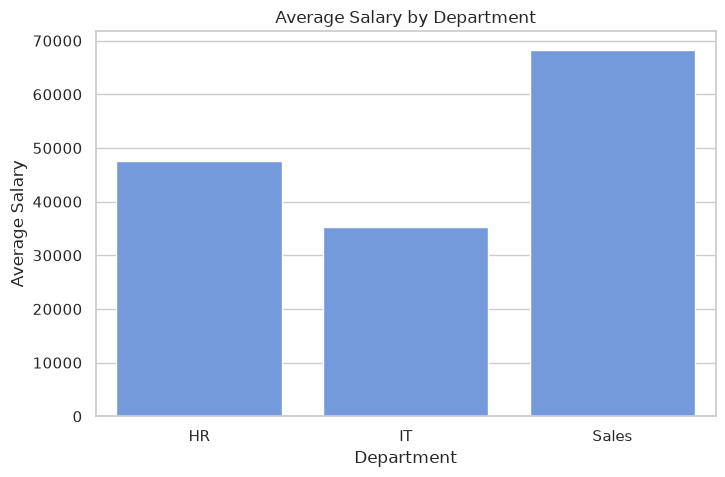

  Department        Salary
0         HR  47666.666667
1         IT  35250.000000
2      Sales  68333.333333


In [7]:
avg_salary = (
    df.groupby("Department", as_index=False)["Salary"]
      .mean()
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=avg_salary,
    x="Department",
    y="Salary",
    color="cornflowerblue"
)

plt.title("Average Salary by Department")
plt.xlabel("Department")
plt.ylabel("Average Salary")
plt.show()

print(avg_salary)

### How to interpret the graph
- The X-axis contains the departments.
- The Y-axis displays the average salary for each department.
- Taller bars indicate higher average salaries.
### Insight obtained: 
In this sample, Sales has the highest average salary, followed by HR and IT. However, the dataset is small, so this is a descriptive comparison, not proof that the same pattern holds across the company.

### AI/ML use case: 
Bar charts help compare average target values across categories and assess whether a categorical feature may be associated with the target.

## Count Plot
Definition: A count plot displays the number of observations in each category.

### Why was it selected?

Unlike the bar chart above, which displays average salary, a count plot directly counts records. It helps us understand how many employees belong to each department.

### Example question: 
Which department has the most employees?

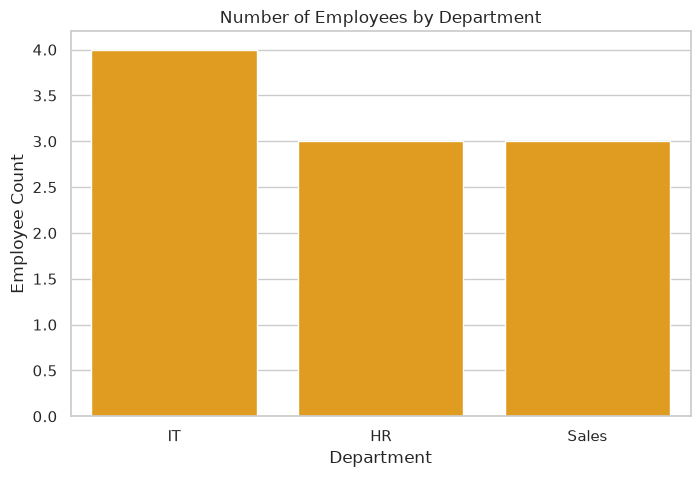

Department
IT       4
HR       3
Sales    3
Name: count, dtype: int64


In [8]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Department",
    color="orange"
)

plt.title("Number of Employees by Department")
plt.xlabel("Department")
plt.ylabel("Employee Count")
plt.show()

print(df["Department"].value_counts())

### How to interpret the graph
- Each bar represents one department.
- The height of each bar represents its employee count.
- Taller bars indicate departments with more employees in the dataset.
### Insight obtained: 
IT has four employees, while HR and Sales each have three. This shows the department distribution in our sample.

### AI/ML use case: 
Count plots are useful for checking class imbalance in classification problems, such as identifying whether a dataset contains many more customers who did not churn than customers who did.

## Scatter Plot
Definition: A scatter plot displays the relationship between two numerical variables using individual points.

### Why was it selected?

A scatter plot helps us examine whether two variables move together, whether the relationship is positive or negative, and whether there are unusual observations.

### Example question: 
Do employees with more experience tend to earn higher salaries?

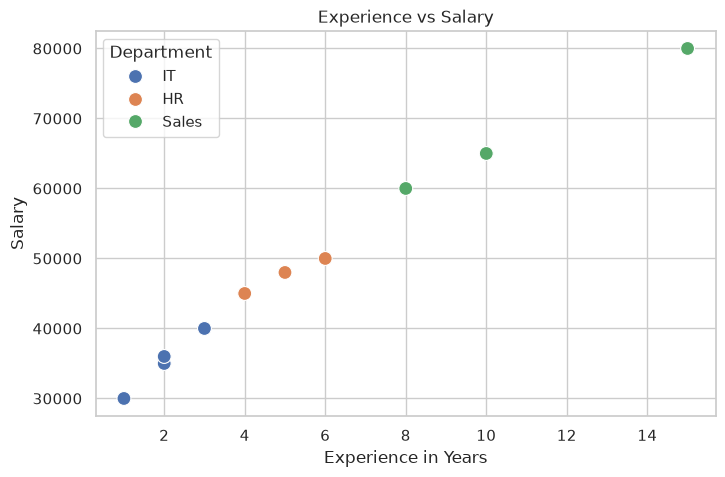

In [9]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Experience",
    y="Salary",
    hue="Department",
    s=100
)

plt.title("Experience vs Salary")
plt.xlabel("Experience in Years")
plt.ylabel("Salary")
plt.show()

### How to interpret the graph
- The X-axis represents years of experience.
- The Y-axis represents salary.
- Each point represents one employee.
- The colors distinguish departments.
- An upward pattern suggests a positive relationship between experience and salary.
### Insight obtained: 
The sample broadly suggests that more experienced employees often earn higher salaries, although salary also varies by department and individual. The chart alone does not establish causation.

### AI/ML use case: 
Scatter plots help detect relationships between numerical features, investigate outliers, and assess whether a linear model may be appropriate.

## Line Plot
Definition: A line plot connects data points in sequence to show how a numerical variable changes across an ordered dimension, commonly time.

### Why was it selected?
A line plot is especially useful for identifying trends, increases, decreases, and fluctuations over time. Employee rows are not time points, so we will create a separate monthly sales dataset for this graph.

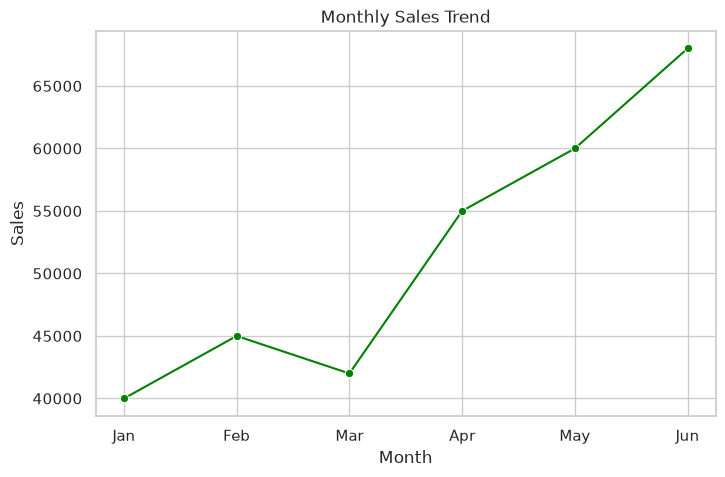

In [11]:
monthly_sales = pd.DataFrame({
    "Month": [
        "Jan", "Feb", "Mar", "Apr", "May", "Jun"
    ],
    "Sales": [
        40000, 45000, 42000, 55000, 60000, 68000
    ]
})

plt.figure(figsize=(8, 5))

sns.lineplot(
    data=monthly_sales,
    x="Month",
    y="Sales",
    marker="o",
    color="green"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.show()

### How to interpret the graph
- The X-axis represents months in chronological order.
- The Y-axis represents sales.
- Upward sections indicate increasing sales.
- Downward sections indicate decreasing sales.
### Insight obtained: 
Sales increase overall from January to June, with a decline from February to March. The largest value in this sample is in June.

### AI/ML use case: 
Line plots help analyze time-series data before forecasting future sales, demand, website traffic, or revenue.

## Violin Plot
Definition: A violin plot combines distribution shape with summary information similar to a box plot. Its width indicates where observations are more concentrated.

### Why was it selected?
A violin plot helps compare the distribution and spread of a numerical variable across categories. Unlike a simple bar chart of averages, it reveals how values are distributed within each group.

### Example question:
How does salary distribution differ across departments?

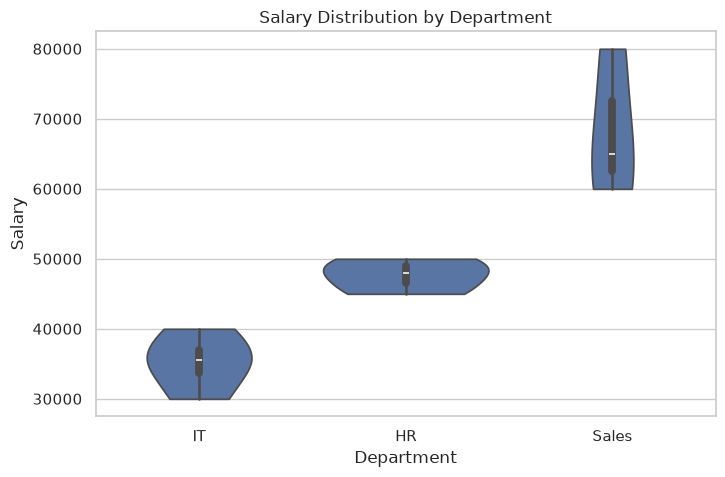

In [12]:
plt.figure(figsize=(8, 5))

sns.violinplot(
    data=df,
    x="Department",
    y="Salary",
    inner="box",
    cut=0
)

plt.title("Salary Distribution by Department")
plt.xlabel("Department")
plt.ylabel("Salary")
plt.show()

### How to interpret the graph
- The X-axis represents departments.
- The Y-axis represents salaries.
- Wider parts of a violin indicate salary values with greater estimated density.
- The inner box summarizes the median and quartiles.
### Insight obtained: 
We can compare the typical salary levels and variability across IT, HR, and Sales. Because each group has only three or four employees, the estimated distribution shapes are based on very little data and should be interpreted cautiously.

### AI/ML use case: 
Violin plots help explore how a numerical feature varies across target classes, such as comparing customer spending between churned and retained customers.

### Pair Plot
Definition: A pair plot displays pairwise relationships among several numerical variables. It shows scatter plots for pairs of features and individual distributions along the diagonal.

### Why was it selected?
When a dataset contains several numerical features, examining every relationship individually can be time-consuming. A pair plot provides an overview of multiple relationships in one figure.
### Example question: 
How are age, experience, salary, and performance related?

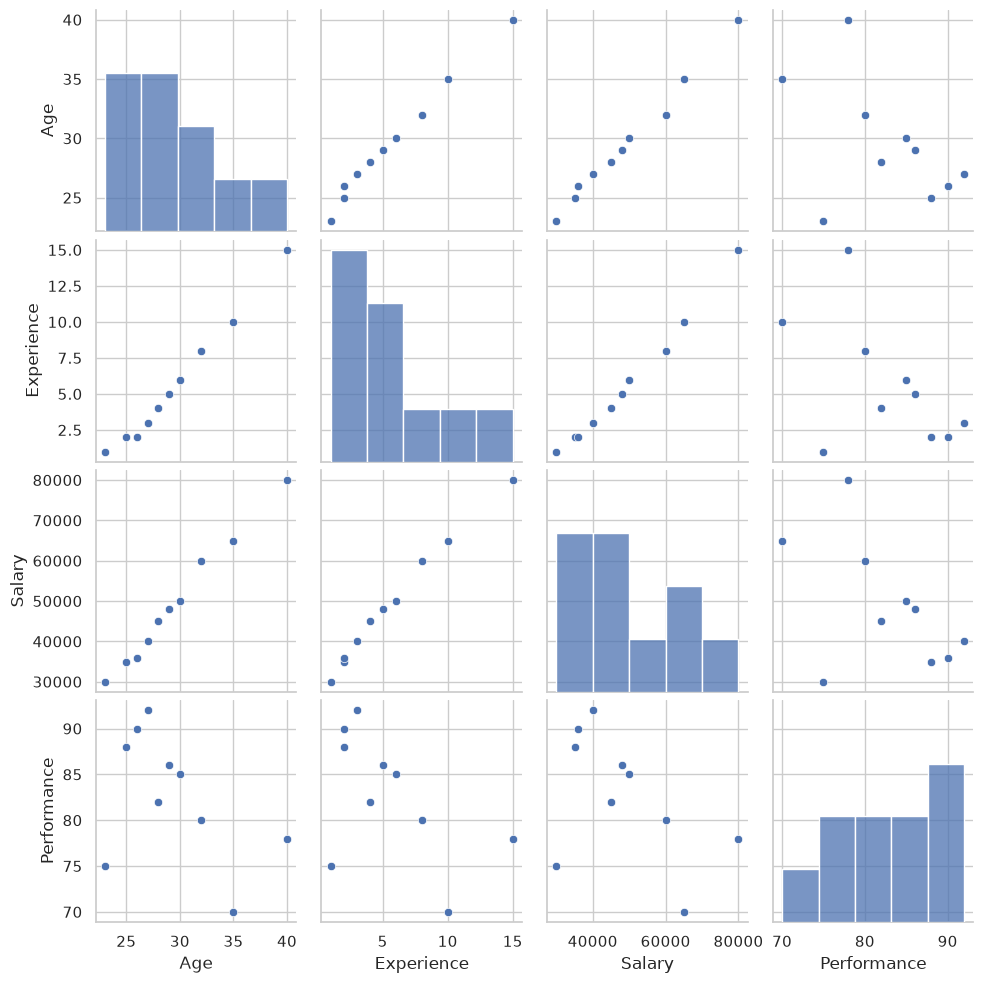

In [13]:
sns.pairplot(
    df[["Age", "Experience", "Salary", "Performance"]],
    diag_kind="hist"
)

plt.show()

### Insight obtained: 
The pair plot lets us examine several relationships at once, including experience versus salary and age versus experience. Any apparent patterns should be verified rather than assumed to be statistically strong.

### AI/ML use case: 
Pair plots support feature exploration and can reveal redundant features, possible nonlinear relationships, and unusual observations before model development.

### Note: 
Pair plots can become crowded when there are many features. Select a meaningful subset rather than plotting every column.

## Heatmap
Definition: A heatmap uses colors to represent numerical values in a matrix. In EDA, it is commonly used to visualize correlations between numerical features.

### Why was it selected?
A correlation heatmap makes it easier to identify pairs of numerical variables that move together. It can also help identify potential multicollinearity among model features.
### Example question: 
Which numerical variables have stronger relationships with one another?

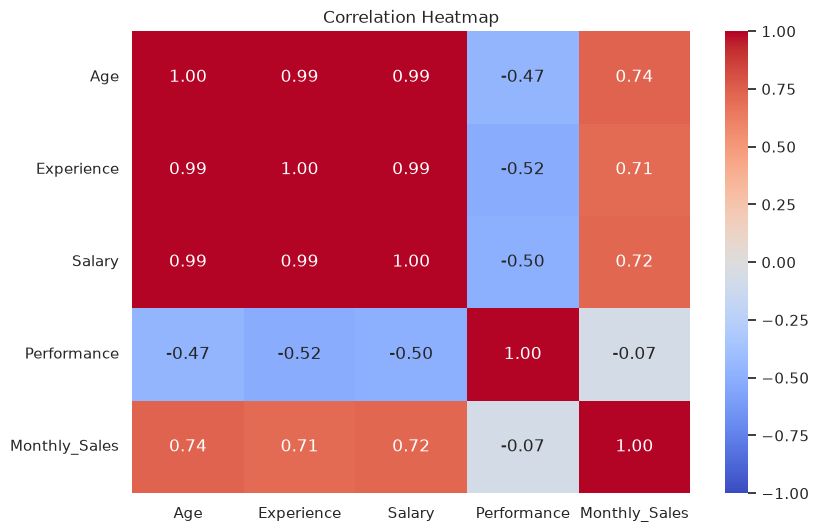

In [14]:
numeric_df = df.select_dtypes(include="number")

correlation = numeric_df.corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap")
plt.show()

### Insight obtained: 
The heatmap gives an overview of the linear relationships among age, experience, salary, performance, and monthly sales. In this small sample, experience and salary are likely to show a positive relationship, but the exact strength should be read from the generated heatmap.

### AI/ML use case: 
Correlation heatmaps help investigate redundant numerical features and potential multicollinearity in regression models.

### Important: 
Correlation does not prove causation, and a low correlation does not rule out a nonlinear relationship. For categorical features, use appropriate methods instead of applying Pearson correlation blindly.

## Distribution Plot
Definition: A distribution plot displays how numerical values are spread across a range. A histogram shows frequencies, while a KDE curve estimates the shape of the underlying distribution.
### Why was it selected?
A distribution plot helps us inspect the shape of numerical data, including concentration, spread, skewness, and possible unusual patterns.
### Example question: How are employee performance scores distributed?

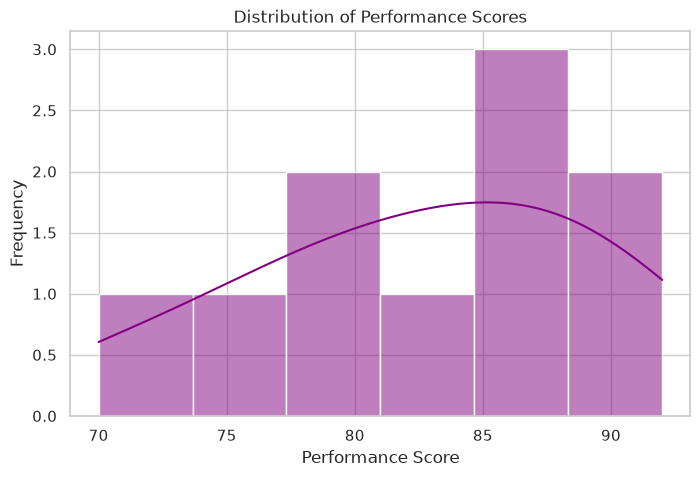

In [15]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Performance",
    kde=True,
    bins=6,
    color="purple"
)

plt.title("Distribution of Performance Scores")
plt.xlabel("Performance Score")
plt.ylabel("Frequency")
plt.show()

### How to interpret the graph
- The bars show the number of employees in score intervals.
- The KDE curve provides a smoothed estimate of the distribution.
- A concentration of values in one region indicates where scores are more common.
- A longer tail on one side may suggest skewness.
### Insight obtained: 
We can identify the performance-score ranges where employees are concentrated and whether scores appear spread out or clustered.

### AI/ML use case: 
Distribution plots help determine whether numerical features may need transformations and whether the training data contains unexpected distribution patterns.

Difference between histogram and distribution plot: A histogram emphasizes frequencies in bins. A histogram with KDE, as shown here, combines those frequencies with a smoothed view of distribution shape. They are related visualizations, not entirely separate types of evidence.